## 1- liabray

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
sns.set(style="darkgrid",font_scale=1.5)
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, ExtraTreesClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score ,f1_score, confusion_matrix, classification_report

### Professional insight

**Purpose:** This cell imports the libraries required for data manipulation, visualisation, statistical analysis, preprocessing, resampling, model training and evaluation. These imports establish the analytical environment; they do not produce a customer insight by themselves.


## 2- reading & analysis

In [2]:
df = pd.read_csv('Churn_Modelling.csv')

### Professional insight

**Insight:** The CSV file is loaded into a Pandas DataFrame for analysis. The subsequent checks will establish its size, structure and data quality before any conclusions are drawn.


In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### Professional insight

**Observation:** The first five records show that the dataset contains customer profile, financial, banking-relationship and target information. `Exited` is the outcome to be predicted (1 = exited, 0 = retained). The preview is useful for checking column names and value formats, but five rows are not sufficient to establish patterns across the full dataset.


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


### Professional insight

**Professional insight:** The dataset contains 10,000 records and 14 columns. All columns have 10,000 non-null values, so this initial structural check indicates no missing values. The data types are appropriate for the initial analysis: numerical fields are stored as integers or floats, while Geography, Gender and Surname are categorical/text fields. This check does not rule out invalid or unusual values.


In [5]:
df.shape

(10000, 14)

### Professional insight

**Professional insight:** The dataset has 10,000 rows and 14 columns. This provides a substantial sample for exploratory analysis and classification. The three identifier fields and the target variable should be distinguished from genuine predictive features during preparation.


In [6]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


### Professional insight

**Professional insight:** The descriptive statistics provide a baseline profile of the numerical variables. Average age is 38.92 years, average credit score is 650.53, average tenure is 5.01 years, average balance is 76,485.89, and average estimated salary is 100,090.24. The median balance (97,198.54) is higher than the mean, suggesting that zero and lower balances pull the mean down. At least 25% of customers have a balance of zero because the first quartile is zero. These are descriptive patterns, not evidence that any variable causes churn.


In [7]:
df.duplicated().sum()

np.int64(0)

### Professional insight

**Data-quality insight:** The duplicate check returns zero, indicating that no fully duplicated rows were detected. This reduces the risk that repeated records will distort descriptive statistics or model training. It does not identify partial duplicates, such as repeated customer IDs with different fields; those can be checked separately if necessary.


In [8]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

### Professional insight

**Data-quality insight:** Every column has zero missing values. Therefore, no missing-value imputation is required for the fields in this dataset. The result does not guarantee that every value is valid—for example, zero balances may be genuine observations rather than missing data.


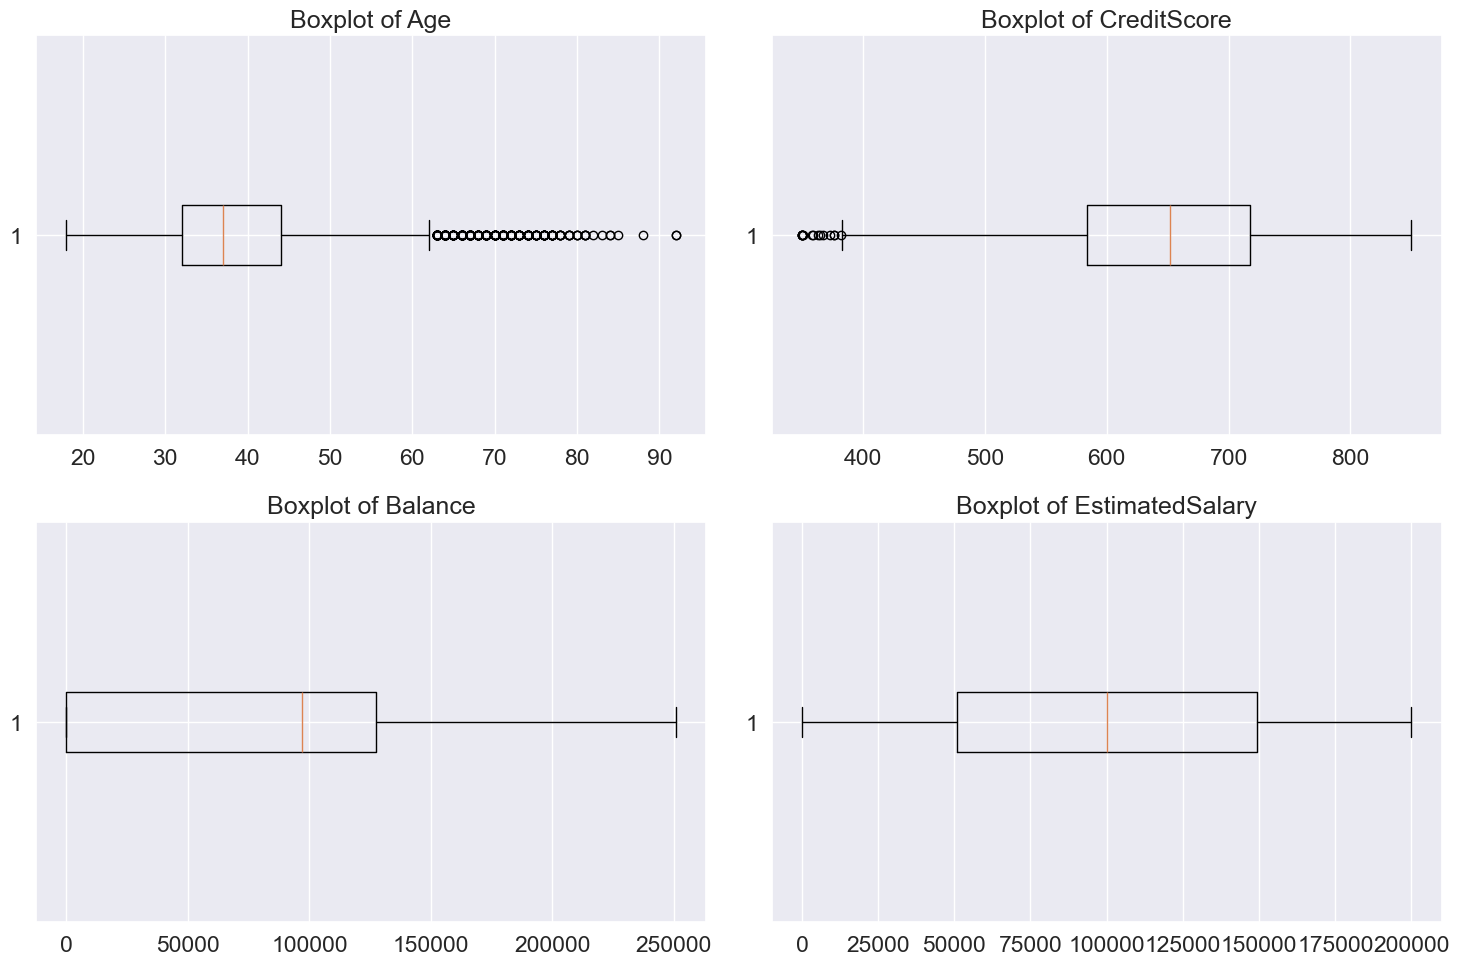

In [9]:
num_feature = ["Age","CreditScore","Balance","EstimatedSalary"]
plt.figure(figsize=(15, 10))
for i, feature in enumerate(num_feature,1):
    plt.subplot(2, 2, i)
    plt.boxplot(df[feature], vert=False)
    plt.title(f'Boxplot of {feature}')
    
plt.tight_layout()
plt.show()

### Professional insight

**Diagram insight – numerical boxplots:** The four boxplots compare the distributions and potential outliers of Age, CreditScore, Balance and EstimatedSalary. A box represents the interquartile range, the central line is the median, and points beyond the whiskers may indicate potential outliers. The plots should be used to identify unusual values for investigation, not to remove observations automatically. Balance includes many zero values, which can create a distinctive distribution. No causal relationship with churn can be inferred from these plots.


In [10]:
df["Geography"].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

### Professional insight

**Geography insight:** France has 5,014 customers (50.14%), Germany has 2,509 (25.09%), and Spain has 2,477 (24.77%). The customer base is therefore concentrated in France, while Germany and Spain have almost equal representation. These are customer counts, not churn rates; a country with more customers may also have more exits simply because its customer base is larger.


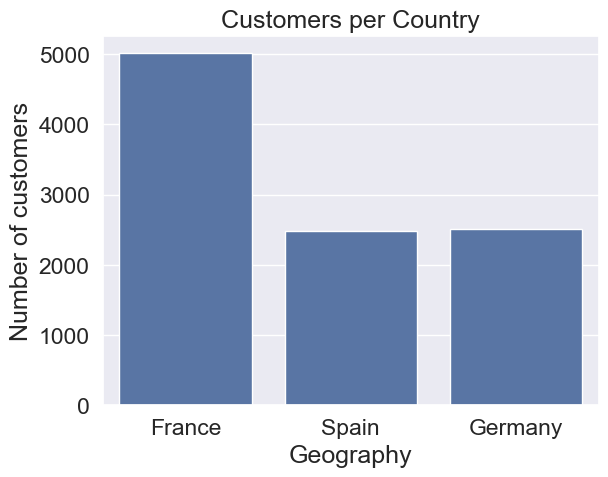

In [11]:
plt.Figure(figsize=(12,6))
sns.countplot(data= df ,x = "Geography")
plt.xlabel("Geography")
plt.ylabel("Number of customers")
plt.title("Customers per Country")
plt.show()

### Professional insight

**Diagram insight – customers per country:** The count plot visualises the geographical distribution and confirms that France is the largest customer segment, with Germany and Spain contributing roughly one quarter each. This helps describe the bank's market composition. To assess retention performance, the next step is to compare the proportion of customers who exited within each country rather than comparing raw counts alone.


In [12]:
checking_credit_avg = df['CreditScore'].mean()
print(f"Average Credit Score: {checking_credit_avg}")
credits_more_than_avg = df[df['CreditScore'] > checking_credit_avg]
credits_less_than_avg = df[df['CreditScore'] <= checking_credit_avg]
print(f"Number of customers with credit score more than average: {credits_more_than_avg.shape[0]}")
print(f"Number of customers with credit score less than or equal to average: {credits_less_than_avg.shape[0]}")

Average Credit Score: 650.5288
Number of customers with credit score more than average: 5063
Number of customers with credit score less than or equal to average: 4937


### Professional insight

**Credit-score insight:** The average credit score is 650.53. There are 5,063 customers above the mean and 4,937 customers at or below it, so the dataset is relatively evenly divided around this threshold. The split is descriptive and does not show whether either group is more likely to leave. A churn-rate comparison by credit-score band would be needed to assess that question.


In [13]:
df['CreditScore'].describe()

count    10000.000000
mean       650.528800
std         96.653299
min        350.000000
25%        584.000000
50%        652.000000
75%        718.000000
max        850.000000
Name: CreditScore, dtype: float64

### Professional insight

**Credit-score insight:** Credit scores range from 350 to 850, with a mean of 650.53 and a median of 652. The close mean and median suggest that the distribution is broadly centred around the mid-600s. The middle 50% of scores lie between 584 and 718. These summary statistics describe the customer credit-score profile but do not establish a relationship with churn.


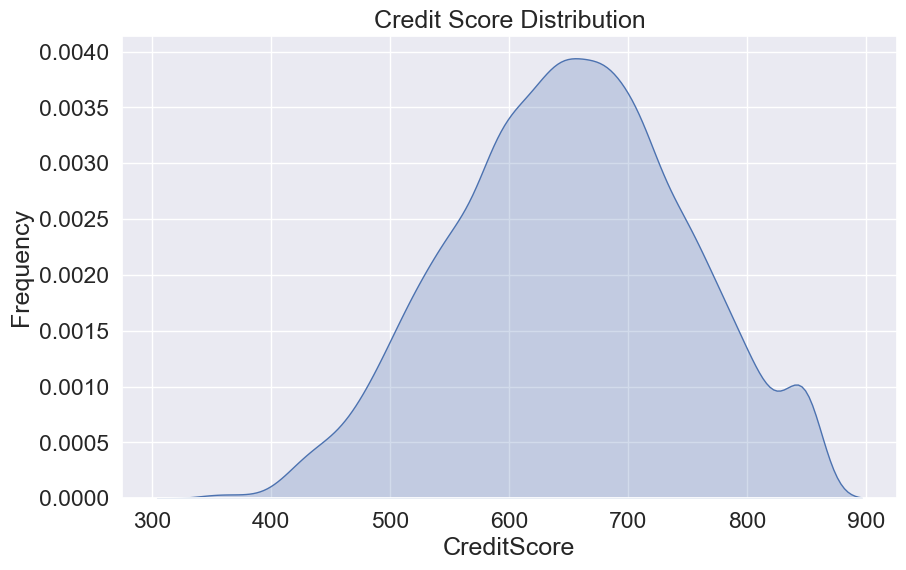

In [14]:
plt.figure(figsize=(10, 6))
sns.kdeplot(
    df["CreditScore"],fill=True
)
plt.title('Credit Score Distribution')
plt.xlabel('CreditScore')
plt.ylabel('Frequency')

plt.show()

### Professional insight

**Diagram insight – credit-score density:** The KDE curve shows where credit scores are concentrated and whether the distribution is skewed or has multiple peaks. Most observations are expected around the centre of the distribution, consistent with the mean and median near 651–652. A KDE is a smoothed estimate of the distribution, not a count of customers at each exact score. It does not show churn differences because the target is not used in this chart.


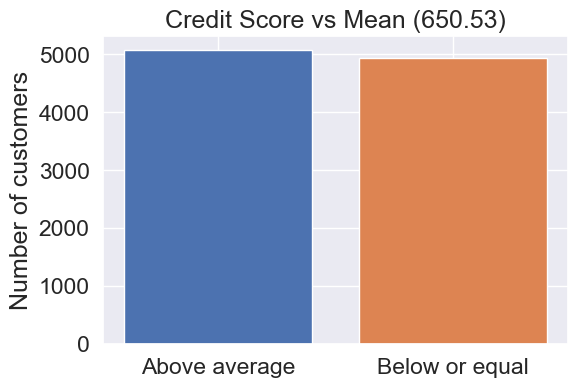

In [15]:
plt.figure(figsize=(6, 4))
plt.bar(['Above average', 'Below or equal'],
        [len(credits_more_than_avg), len(credits_less_than_avg)],
        color=['#4C72B0', '#DD8452'])
plt.title(f'Credit Score vs Mean ({checking_credit_avg:.2f})')
plt.ylabel('Number of customers')
plt.show()

### Professional insight

**Diagram insight – credit score relative to the mean:** The bar chart shows a near-even split: 5,063 customers score above the mean and 4,937 score at or below it. The difference is small, so the mean divides the sample into two similarly sized groups. This threshold is a convenient descriptive reference, not a credit-risk category or a proven churn boundary.


In [16]:
gender_count = df["Gender"].value_counts()

### Professional insight

**Purpose:** This cell counts customers in each gender category. The resulting counts describe the composition of the dataset; churn differences must be assessed separately using the target variable.


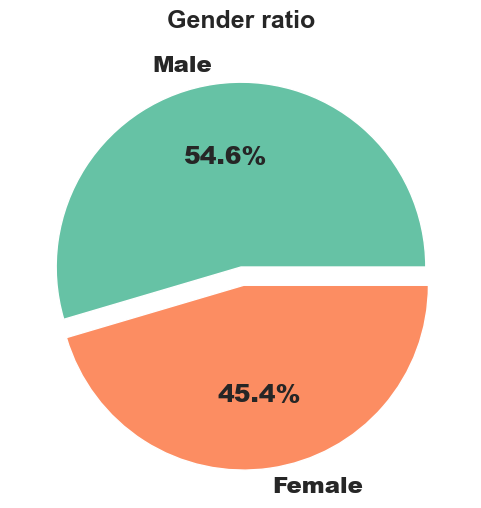

In [17]:
plt.figure(figsize=(6, 6))
plt.pie(
    gender_count,
    labels=gender_count.index, autopct="%1.1f%%",colors=sns.set_palette("Set2"),
        textprops={"fontweight":"black"},explode=[0, 0.1]
)
plt.title("Gender ratio", fontweight="bold")
plt.show()

### Professional insight

**Diagram insight – gender ratio:** The pie chart displays the proportion of male and female customers in the dataset. It is useful for understanding sample composition, but a larger gender segment does not imply a higher churn tendency. To evaluate gender and retention, compare the exit percentage within each gender rather than the overall gender share.


In [18]:
df["Age"].describe()

count    10000.000000
mean        38.921800
std         10.487806
min         18.000000
25%         32.000000
50%         37.000000
75%         44.000000
max         92.000000
Name: Age, dtype: float64

### Professional insight

**Age insight:** The average customer age is 38.92 years and the median is 37. The middle 50% of customers are between 32 and 44 years old, while the full observed range is 18–92. The mean being slightly above the median suggests that older observations pull the average upward. Age bands and their individual churn rates would provide a more actionable retention analysis.


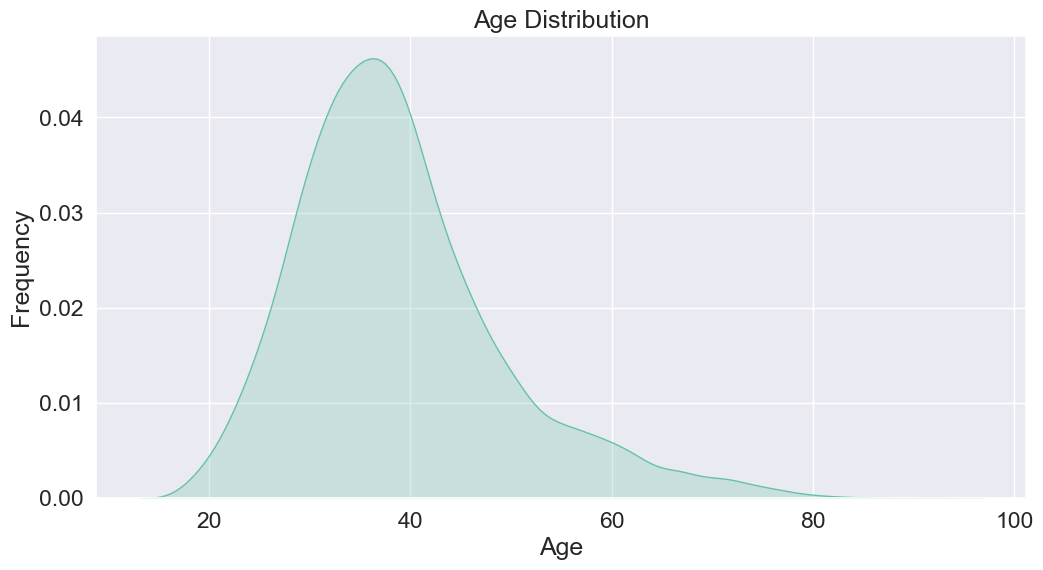

In [19]:
plt.figure(figsize=(12, 6))
sns.kdeplot(df["Age"],fill= True)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

### Professional insight

**Diagram insight – age distribution:** The KDE plot shows the concentration and shape of customer ages. It helps identify the typical age range and whether the distribution is skewed. The summary statistics indicate that customers are concentrated around the late 30s, with a longer upper-age range. This plot describes all customers together; it does not establish which ages have higher churn. A churn rate by age group is required for that conclusion.


In [20]:
df['Tenure'].value_counts()

Tenure
2     1048
1     1035
7     1028
8     1025
5     1012
3     1009
4      989
9      984
6      967
10     490
0      413
Name: count, dtype: int64

### Professional insight

**Tenure insight:** Customer tenure is distributed across 0–10 years. The largest individual groups are customers with 2 years (1,048) and 1 year (1,035), while 490 customers have 10 years of tenure and 413 have zero years. The average tenure is approximately 5.01 years. The relatively small 10-year group may reflect the dataset's tenure distribution; compare churn proportions by tenure before drawing retention conclusions.


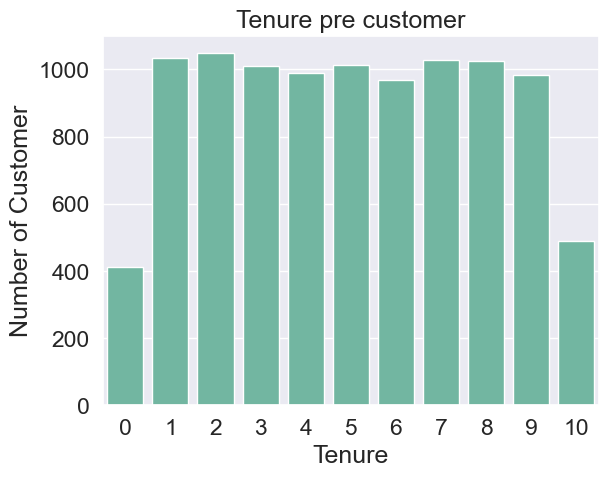

In [21]:
plt.Figure(figsize=(12,6))
sns.countplot(data= df,x= "Tenure")
plt.xlabel("Tenure")
plt.ylabel("Number of Customer")
plt.title("Tenure pre customer")
plt.show()

### Professional insight

**Diagram insight – tenure distribution:** The count plot shows how many customers fall into each tenure category. Counts are broadly distributed across years 1–9, with fewer customers at 0 and 10 years. This indicates that the sample is not dominated by a single tenure category. The chart does not show whether newer or longer-standing customers are more likely to exit; that requires a tenure-versus-churn rate analysis.


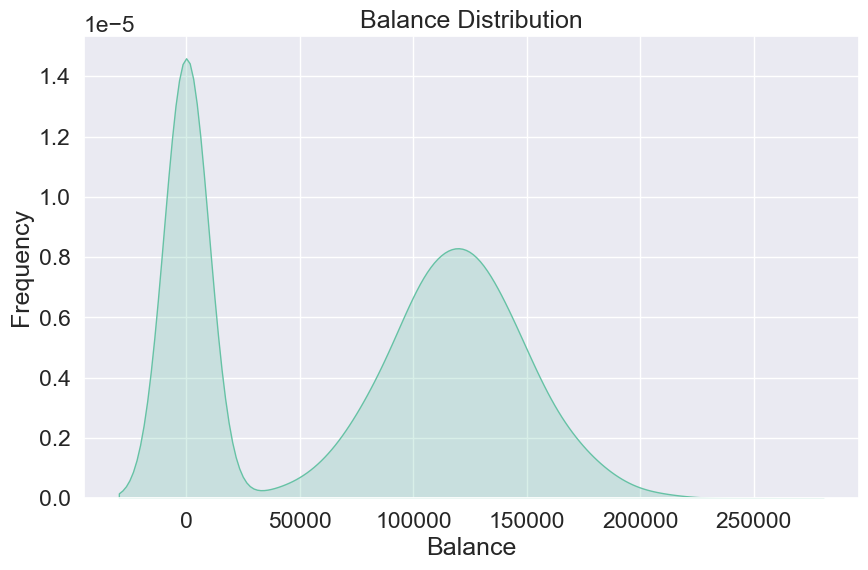

In [22]:
plt.figure(figsize=(10, 6))
sns.kdeplot(df["Balance"],fill = True)
plt.title('Balance Distribution')
plt.xlabel('Balance')
plt.ylabel('Frequency')
plt.show()

### Professional insight

**Diagram insight – account balance distribution:** The KDE plot illustrates the distribution of customer balances. The descriptive statistics show a median of 97,198.54, a mean of 76,485.89 and a first quartile of zero. This indicates a substantial concentration of zero or low balances and a difference between the mean and median. Because zero balances may be legitimate, they should be investigated rather than automatically treated as missing values. This chart alone does not establish how balance relates to churn.


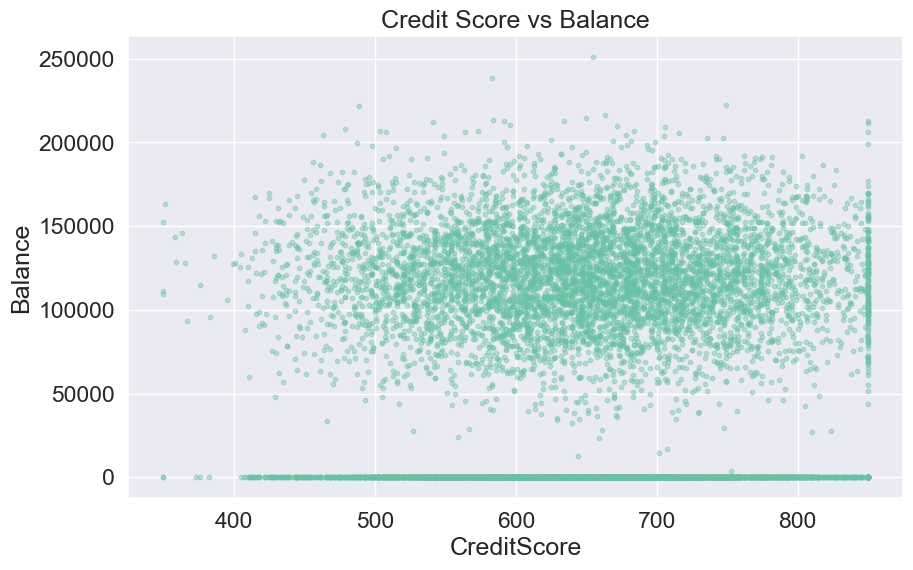

In [23]:
plt.figure(figsize=(10, 6))
plt.scatter(df["CreditScore"], df["Balance"], alpha=0.4, s=10)
plt.xlabel("CreditScore")
plt.ylabel("Balance")
plt.title("Credit Score vs Balance")
plt.show()

### Professional insight

**Diagram insight – credit score versus balance:** Each point represents a customer, allowing a visual check for a relationship between credit score and account balance. The scatter plot can reveal clusters, spread and possible outliers. If there is no clear upward or downward pattern, a strong linear association is not visually evident. Overlapping points may hide density. Churn is not encoded in this chart, so it cannot explain customer exits; colouring points by `Exited` or comparing churn rates across balance bands would add that information.


In [24]:
df["NumOfProducts"].value_counts()

NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

### Professional insight

**Product-count insight:** 5,084 customers have one product, 4,590 have two, 266 have three and 60 have four. Therefore, 96.74% of customers use one or two products, while only 3.26% use three or four. The portfolio is concentrated in one- and two-product relationships. This may suggest a cross-selling opportunity, but product count should not be assumed to reduce churn without comparing exit rates for each product group.


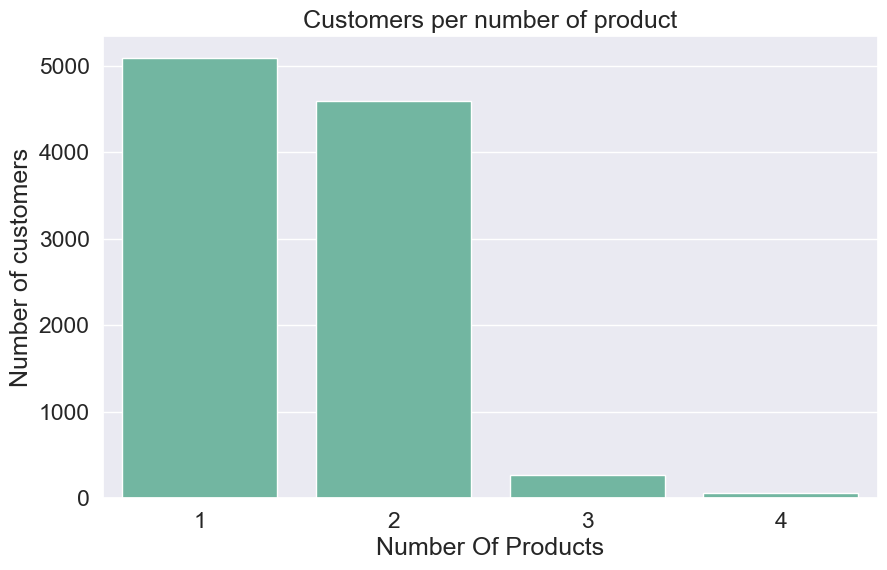

In [25]:
plt.figure(figsize=(10, 6))
sns.countplot(data = df , x="NumOfProducts")
plt.xlabel("Number Of Products")
plt.ylabel("Number of customers")
plt.title("Customers per number of product")
plt.show()

### Professional insight

**Diagram insight – customers by number of products:** The count plot confirms that one- and two-product customers make up nearly the entire dataset. Three- and four-product customers are comparatively rare. Because the higher-product groups are small, their churn rates may be less stable and should be interpreted with their sample sizes in mind. The chart shows customer volume, not retention performance.


In [26]:
has_card =df["HasCrCard"].value_counts()
print(has_card)

HasCrCard
1    7055
0    2945
Name: count, dtype: int64


### Professional insight

**Credit-card ownership insight:** 7,055 customers (70.55%) have a credit card, while 2,945 (29.45%) do not. Credit-card ownership is common in this customer base. This variable indicates whether a card is held, not whether it is actively used. To determine whether ownership is associated with retention, calculate the churn rate separately for cardholders and non-cardholders.


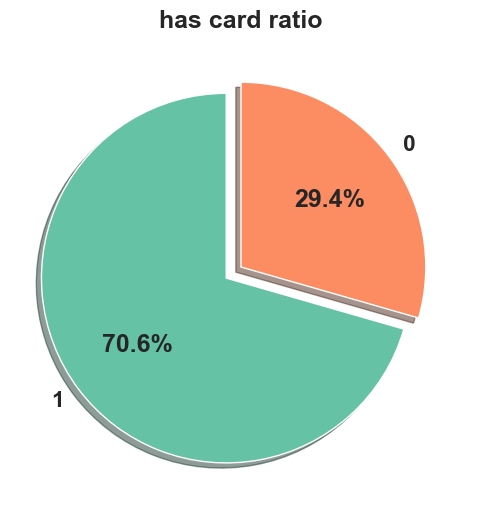

In [27]:


plt.figure(figsize=(6, 6))
plt.pie(
    has_card,
    labels=has_card.index,
    autopct="%1.1f%%",
    colors=sns.color_palette("Set2"),
    textprops={"fontweight": "bold"},
    explode=[0.1, 0],        
    startangle=90,
    shadow=True
)
plt.title("has card ratio", fontweight="bold")
plt.show()

### Professional insight

**Diagram insight – credit-card ratio:** The pie chart visualises the 70.55% of customers with a credit card and 29.45% without one. It confirms that most customers hold a card. This is a profile insight rather than a churn insight; the chart does not distinguish customers who stayed from those who exited.


In [28]:
is_active_count=df['IsActiveMember'].value_counts()
print(is_active_count)

IsActiveMember
1    5151
0    4849
Name: count, dtype: int64


### Professional insight

**Activity insight:** There are 5,151 active members (51.51%) and 4,849 inactive members (48.49%). The dataset is therefore almost evenly split by activity status. The substantial inactive segment may be worth investigating for engagement opportunities. However, inactivity should only be treated as a churn indicator if its within-group exit rate is demonstrably higher.


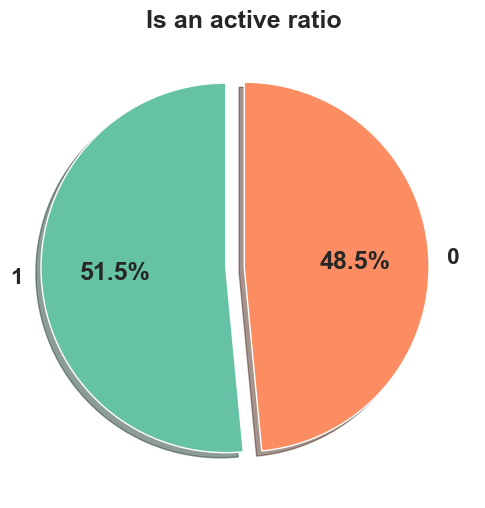

In [29]:
plt.figure(figsize=(6, 6))
plt.pie(
    is_active_count,
    labels=is_active_count.index,
    autopct="%1.1f%%",
    colors=sns.color_palette("Set2"),
    textprops={"fontweight": "bold"},
    explode=[0.1, 0],      
    startangle=90,
    shadow=True
)
plt.title("Is an active ratio", fontweight="bold")
plt.show()

### Professional insight

**Diagram insight – active-member ratio:** The pie chart shows a near-even split between active and inactive members, with a slight majority classified as active. This highlights that a large proportion of the customer base is not currently classified as active. A useful follow-up is to compare churn rates for active and inactive customers and quantify the difference in percentage points.


In [30]:
df['EstimatedSalary'].describe()

count     10000.000000
mean     100090.239881
std       57510.492818
min          11.580000
25%       51002.110000
50%      100193.915000
75%      149388.247500
max      199992.480000
Name: EstimatedSalary, dtype: float64

### Professional insight

**Estimated-salary insight:** Estimated salary has a mean of 100,090.24 and a median of 100,193.92, which are very close. The middle 50% of values range from 51,002.11 to 149,388.25, and the overall range is approximately 11.58 to 199,992.48. The similarity between mean and median suggests a broadly balanced distribution. Estimated salary is not the same as account balance, income verification or customer profitability.


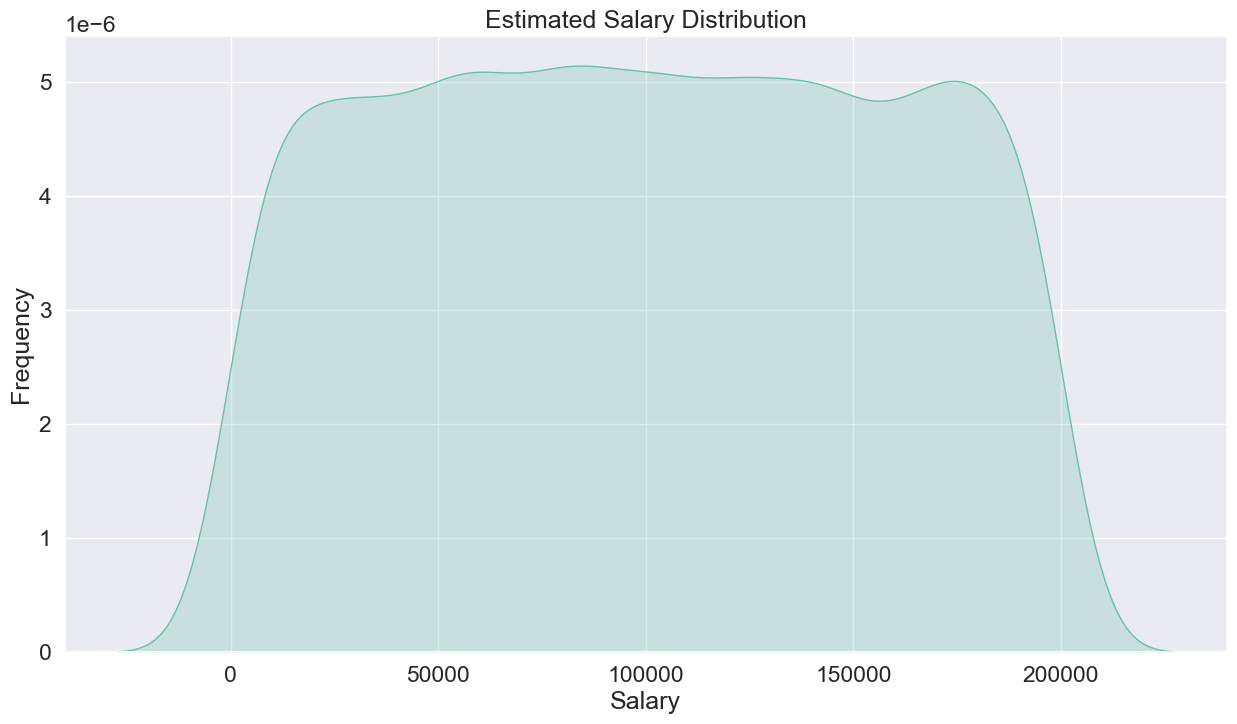

In [31]:
plt.figure(figsize=(15, 8))

sns.kdeplot(df['EstimatedSalary'], fill=True, palette="Set2")
plt.title('Estimated Salary Distribution')
plt.xlabel('Salary')
plt.ylabel('Frequency')

plt.show()

### Professional insight

**Diagram insight – estimated salary distribution:** The KDE plot displays the spread of estimated salaries. The mean and median are almost identical, suggesting that the distribution is reasonably centred around 100,000. The chart helps identify the overall shape and spread, but it does not show whether salary is associated with churn. A salary-band churn analysis would be required to investigate that relationship.


In [32]:
Exited_count=df["Exited"].value_counts()
print(Exited_count)

Exited
0    7963
1    2037
Name: count, dtype: int64


### Professional insight

**Target-variable insight:** The dataset contains 7,963 retained customers (Exited = 0) and 2,037 exited customers (Exited = 1). The overall churn rate is 20.37%, while 79.63% of customers remain. This means the target classes are imbalanced: retained customers are almost four times as numerous as exited customers. Model evaluation should therefore include precision, recall, F1-score and suitable threshold-independent metrics, not accuracy alone.


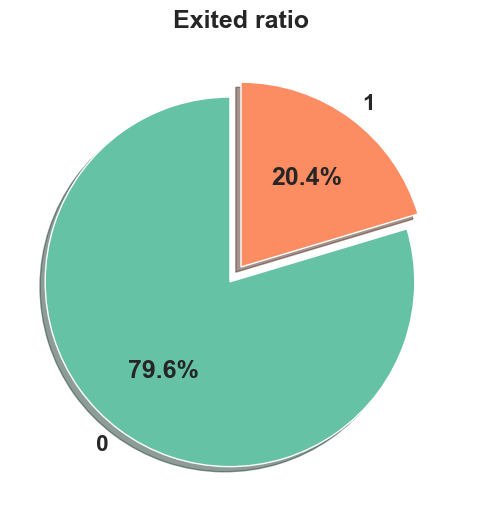

In [33]:
plt.figure(figsize=(6, 6))
plt.pie(
    Exited_count,
    labels=Exited_count.index,
    autopct="%1.1f%%",
    colors=sns.color_palette("Set2"),
    textprops={"fontweight": "bold"},
    explode=[0.1, 0],        
    startangle=90,
    shadow=True
)
plt.title("Exited ratio", fontweight="bold")
plt.show()

### Professional insight

**Diagram insight – exited ratio:** The pie chart shows that 20.37% of customers exited and 79.63% remained. Roughly one customer in five has left, making retention a meaningful business issue. Because the target is imbalanced, a model that predicts every customer as retained would achieve 79.63% accuracy while detecting no churners. This is why recall and precision are essential when assessing the models.


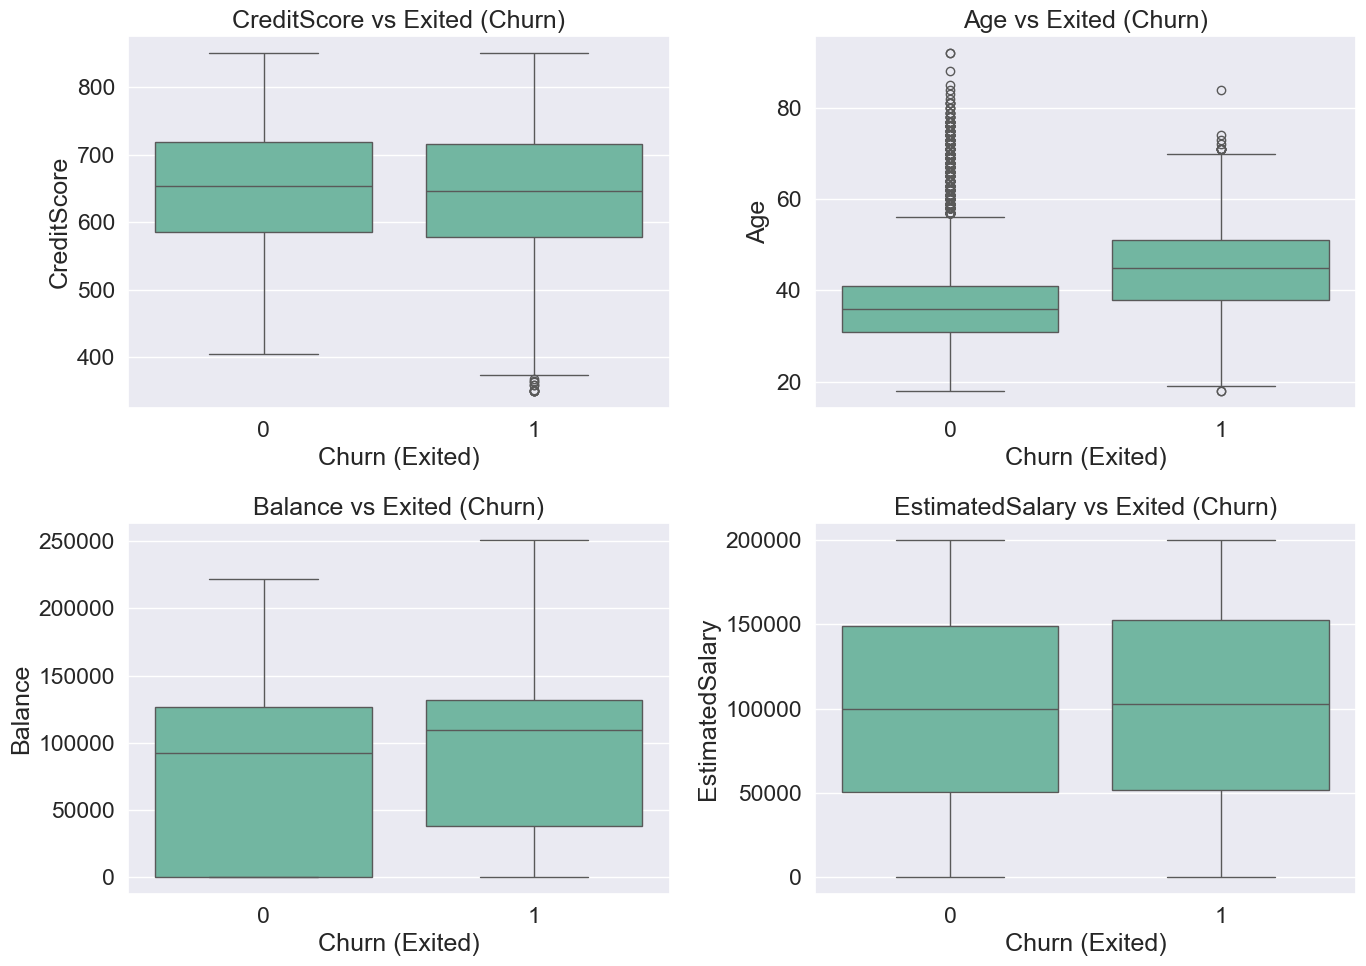

In [34]:
numerical_features = ['CreditScore', 'Age', 'Balance', 'EstimatedSalary']
plt.figure(figsize=(14, 10))
for i, feature in enumerate(numerical_features, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(x='Exited', y=feature, data=df)
    plt.title(f'{feature} vs Exited (Churn)')
    plt.xlabel('Churn (Exited)')
    plt.ylabel(feature)

plt.tight_layout()
plt.show()


### Professional insight

**Diagram insight – numerical features versus churn:** These boxplots compare CreditScore, Age, Balance and EstimatedSalary for customers who stayed and exited. Compare the medians, interquartile ranges and overlap between the two target groups. A visible difference suggests a potential association worth testing, but overlapping distributions indicate that no single variable perfectly separates the groups. Boxplots do not quantify churn probability or prove causation. Because the plots show raw values, differences should be interpreted in each feature's own scale.


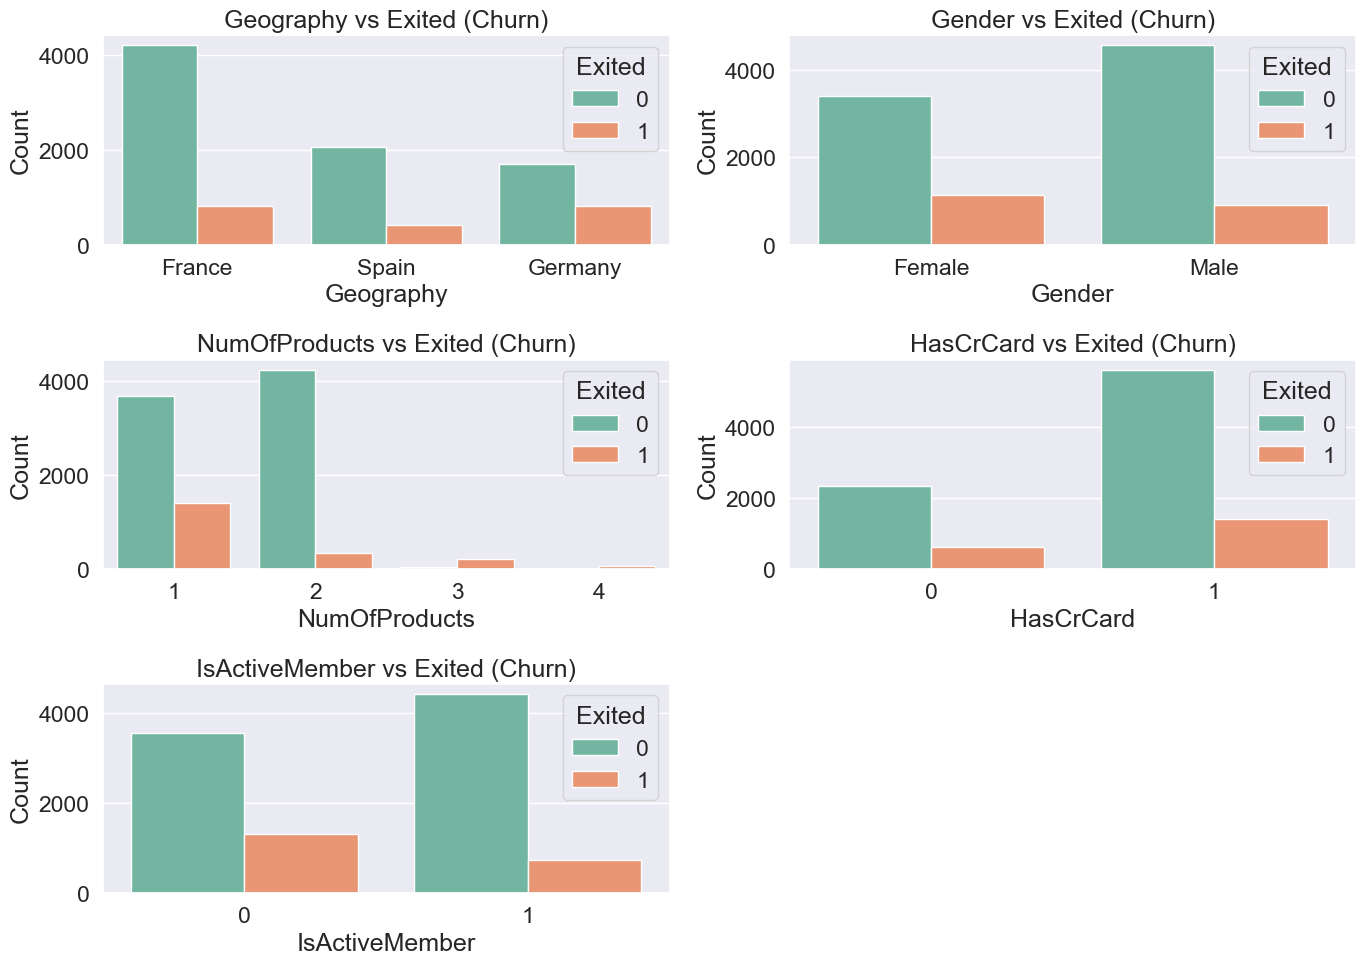

In [35]:
categorical_features = ['Geography', 'Gender', 'NumOfProducts', 'HasCrCard', 'IsActiveMember']
plt.figure(figsize=(14, 10))
for i, feature in enumerate(categorical_features, 1):
    plt.subplot(3, 2, i)
    sns.countplot(x=feature, hue='Exited', data=df)
    plt.title(f'{feature} vs Exited (Churn)')
    plt.xlabel(feature)
    plt.ylabel('Count')

plt.tight_layout()
plt.show()


### Professional insight

**Diagram insight – categorical features versus churn:** These count plots compare exited and retained customer counts across Geography, Gender, NumOfProducts, HasCrCard and IsActiveMember. They help identify segments where the number of exits appears larger. However, raw counts are affected by segment size. For fair comparisons, calculate the exit percentage within each category (for example, exits divided by all German customers), and show sample sizes alongside those rates.


In [36]:
numerical_features_with_target = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary', 'Exited']


### Professional insight

**Purpose:** This cell selects numerical variables and the target for the correlation analysis. Including `Exited` allows the matrix to show each feature's linear correlation with the binary outcome. Correlation is descriptive and may miss nonlinear or interaction effects.


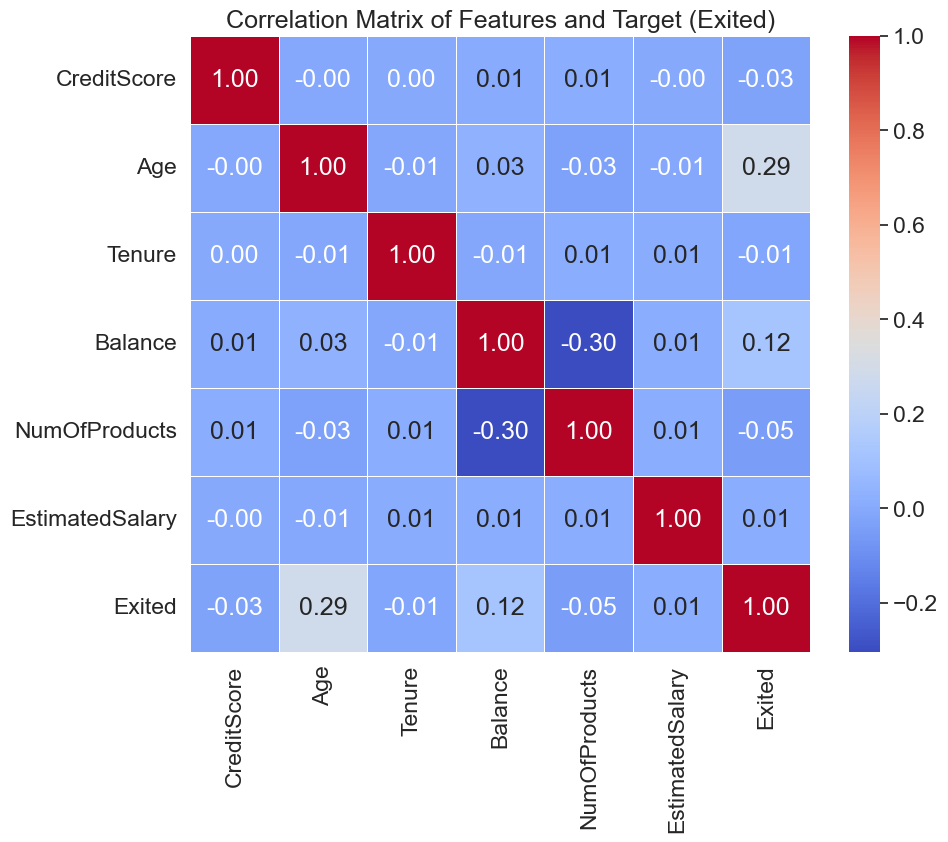

In [37]:
correlation_matrix = df[numerical_features_with_target].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Features and Target (Exited)')
plt.show()

### Professional insight

**Diagram insight – correlation matrix:** The heatmap summarises pairwise Pearson correlations among the selected numerical variables and `Exited`. Values near +1 indicate a strong positive linear relationship, values near -1 a strong negative linear relationship, and values near 0 little linear relationship. Correlations with the binary target can help screen for associations, but they do not prove causation and may understate nonlinear patterns. This matrix excludes categorical variables and should not be treated as a complete feature-importance ranking.


In [38]:
df.drop(columns =['RowNumber', 'CustomerId', 'Surname'], inplace=True )

### Professional insight

**Preparation insight:** The columns `RowNumber`, `CustomerId` and `Surname` are removed because they are identifiers rather than direct measures of customer behaviour or financial circumstances. Removing them reduces the risk that the model learns arbitrary identifiers. The decision is appropriate for this modelling objective, although customer IDs may still be retained separately for operational reporting after predictions are generated.


In [39]:
X = df.iloc[:,:-1]
y= df.iloc[:,-1]

### Professional insight

**Preparation insight:** The feature matrix `X` contains all columns except the final target column, while `y` contains the `Exited` labels. Separating predictors from the outcome is a standard supervised-learning step. It is important to confirm that `Exited` is indeed the final column before relying on positional selection; selecting by column name is generally clearer and more robust.


In [40]:
X = pd.get_dummies(X, columns=['Geography', 'Gender'], drop_first=False)

### Professional insight

**Preparation insight:** One-hot encoding converts the categorical Geography and Gender variables into numerical indicator columns so that the algorithms can process them. With `drop_first=False`, all category indicators are retained. For tree-based models this is generally workable; for linear models, retaining every dummy category alongside an intercept can create perfect multicollinearity. A consistent encoding strategy should be fitted within a training-only preprocessing pipeline.


In [41]:
scale = StandardScaler()
numerical_cols = ["CreditScore","Age","Tenure","Balance","EstimatedSalary"]
X[numerical_cols] = scale.fit_transform(X[numerical_cols])

### Professional insight

**Methodological note:** StandardScaler transforms the selected numerical features to a common scale using the mean and standard deviation. This is important for distance- and margin-based models such as KNN, SVC and Logistic Regression. However, this code fits the scaler on the full dataset before the train-test split, allowing information from the test feature distribution into preprocessing. For a valid evaluation, split first and fit the scaler only on `X_train`, preferably inside a Scikit-learn Pipeline.


In [42]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Professional insight

**Methodological insight:** The data is divided into 80% training observations and 20% test observations, using `random_state=42` for reproducibility. The test set is intended to represent unseen customers and provide an independent estimate of model performance. Because churn is imbalanced, a stratified split (`stratify=y`) should be used to preserve the class proportions in both sets. In this notebook, scaling was already fitted before this split, so the preprocessing leakage should be corrected.


In [43]:
smote= SMOTE(random_state=42)
X_train,y_train = smote.fit_resample(X_train, y_train)
print("Resampled X_train shape:", X_train.shape)
print("Resampled y_train shape:", y_train.shape)

Resampled X_train shape: (12712, 13)
Resampled y_train shape: (12712,)


### Professional insight

**SMOTE insight:** SMOTE increases the minority class in the training set by creating synthetic examples. The resampled training data contains 12,712 rows, with 6,356 observations in each class, so the training classes are balanced after resampling. The test set remains untouched, which is appropriate. However, SMOTE is applied after one-hot encoding, and ordinary SMOTE can create fractional dummy-variable values that do not represent valid categories. Consider SMOTENC for mixed categorical/numerical data, or compare with class-weighted models. Resampling must remain inside each training fold during cross-validation.


In [44]:
lr= LogisticRegression()
lr.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


### Professional insight

**Model insight – Logistic Regression:** Logistic Regression is fitted using the resampled training data. It provides a useful baseline because it is relatively interpretable and estimates the relationship between predictors and the probability of churn. Its performance should be assessed on the untouched test set, with particular attention to recall and precision because the target classes are imbalanced.


In [45]:
print(lr.score(X_train,y_train))

0.7347388294524858


### Professional insight

**Training-performance insight:** Logistic Regression achieves approximately 73.47% accuracy on the resampled training data. Since the training set has been balanced by SMOTE, this score is not directly comparable with the accuracy on the naturally imbalanced test set. It indicates the model's fit on the resampled observations, but should be interpreted together with test metrics and cross-validation.


In [46]:
print(lr.score(X_test,y_test))

0.739


### Professional insight

**Test-performance insight:** Logistic Regression achieves 73.90% accuracy on the test set. This is below the 79.63% accuracy of a simple majority-class baseline, so accuracy alone makes this model look weak. However, the model identifies some churners, so its recall and precision provide additional information about its usefulness. The confusion matrix and class-specific metrics are more informative than accuracy alone.


In [47]:
y_pred = lr.predict(X_test)

### Professional insight

**Purpose:** This cell generates churn predictions for the test observations using Logistic Regression. These predictions are then compared with the true `y_test` labels to calculate performance metrics and the confusion matrix.


In [48]:
lr_acc = accuracy_score(y_test,y_pred)
lr_pre = precision_score(y_test,y_pred)
lr_rec= recall_score(y_test,y_pred)
print(f"logistic regrssion accuracy score: {lr_acc}")
print(f"logistic Regrssion precision score:{lr_pre}")
print(f"logistic Regrssion recall score:{lr_rec}")

logistic regrssion accuracy score: 0.739
logistic Regrssion precision score:0.4009216589861751
logistic Regrssion recall score:0.6641221374045801


### Professional insight

**Logistic Regression evaluation:** The model records 73.90% accuracy, 40.09% precision and 66.41% recall. Precision indicates that about 4 in 10 customers flagged as churners actually exited; recall indicates that the model identifies about two-thirds of all actual churners. The relatively low precision means many retention alerts may be false positives. The appropriate balance depends on the cost of contacting customers versus the cost of missing a potential exit.


The confusion matrix of logistic reg.[[1217  390]
 [ 132  261]]


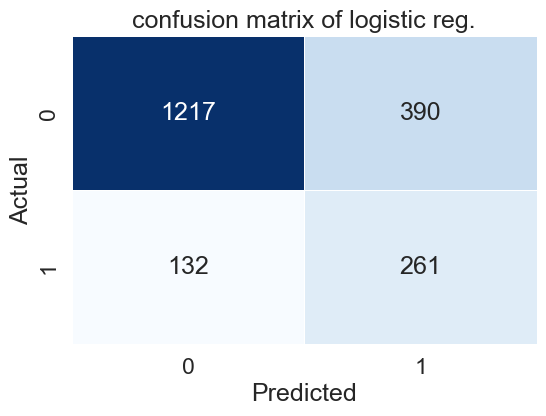

In [49]:
confusion_matrix = confusion_matrix(y_test,y_pred)
print(f"The confusion matrix of logistic reg.{confusion_matrix}")
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Blues', linewidths=.5, cbar=False)
plt.title("confusion matrix of logistic reg.")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Professional insight

**Confusion-matrix insight – Logistic Regression:** The matrix is `[[1217, 390], [132, 261]]` (rows = actual class, columns = predicted class). The model correctly identifies 1,217 retained customers and 261 exited customers. It incorrectly flags 390 retained customers as churners and misses 132 actual churners. In practical terms, the model catches 261 of the 393 churners in the test set, but generates a substantial number of false alarms. This illustrates why recall and precision must be considered together.


In [50]:
param_grid = {'kernel': ['linear', 'poly', 'rbf'],
              'C': [0.1, 1, 10]}

svm = SVC()

### Professional insight

**Purpose:** This cell defines the SVC hyperparameter search space. It tests linear, polynomial and radial-basis-function kernels and three values of `C`. The parameter `C` controls the penalty for classification errors; the kernel determines how the model represents decision boundaries.


In [51]:
grid_search = GridSearchCV(svm, param_grid, cv=5)
grid_search.fit(X, y)

,estimator,SVC()
,param_grid,"{'C': [0.1, 1, ...], 'kernel': ['linear', 'poly', ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,10


### Professional insight

**Critical methodological issue – SVC tuning:** GridSearchCV is fitted on the complete dataset (`X, y`) rather than on the training set only. This exposes the hyperparameter-selection process to the eventual test observations. Consequently, the later SVC test score is not an independent estimate and is likely optimistic. The correct approach is to run GridSearchCV on `X_train, y_train` only, ideally using a Pipeline for preprocessing and stratified cross-validation, then evaluate the selected model once on `X_test`.


In [52]:
best_model = grid_search.best_estimator_
best_model

,C,10
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


### Professional insight

**SVC tuning result:** The search selects an SVC with `C=10` (the default kernel is RBF because no other kernel is displayed in the estimator). This is the best configuration among the tested combinations according to the cross-validation score used by GridSearchCV. Because the search was performed on the full dataset, this selected configuration and its reported test performance require re-evaluation using training data only.


In [53]:
print(best_model.score(X_train, y_train))

0.7507079924480805


### Professional insight

**SVC training-score insight:** The selected SVC reports approximately 75.07% accuracy on the resampled training data. This score is not directly comparable with the naturally distributed test score because the training data was balanced using SMOTE. Also, the SVC was selected using a search that included the test observations, so the evaluation procedure needs to be corrected before drawing conclusions.


In [54]:
print(best_model.score(X_test, y_test))

0.882


### Professional insight

**SVC test-score insight:** The notebook reports 88.20% test accuracy, but this result is not trustworthy as an independent estimate because GridSearchCV was fitted on the full dataset, including the test observations. The score should be recalculated after tuning only on the training set. Do not select SVC as the winning model based on this figure until the leakage is fixed.


In [55]:
y_pred = best_model.predict(X_test)

### Professional insight

**Purpose:** This cell generates SVC predictions for the test observations. These predictions feed the precision, recall, accuracy and confusion-matrix calculations in the following cells. Because the SVC tuning step used the full dataset, these metrics also require re-evaluation after correcting the procedure.


In [56]:
svc_acc = accuracy_score(y_test, y_pred)
svc_per = precision_score(y_test, y_pred)
svc_rec = recall_score(y_test, y_pred)
print(f" SVM best model accuracy score:{svc_acc}")
print(f"SVM best model precision_score: {svc_per}")
print(f"SVM best model recall_score: {svc_rec}")

 SVM best model accuracy score:0.882
SVM best model precision_score: 0.8284518828451883
SVM best model recall_score: 0.5038167938931297


### Professional insight

**SVC evaluation (provisional):** The notebook reports 88.20% accuracy, 82.85% precision and 50.38% recall. If these results were obtained from a valid independent test set, they would indicate that churn alerts are often correct but the model misses about half of actual churners. However, the test data influenced hyperparameter selection, so these values are provisional and must not be used for a final model comparison until the search is repeated using training data only.


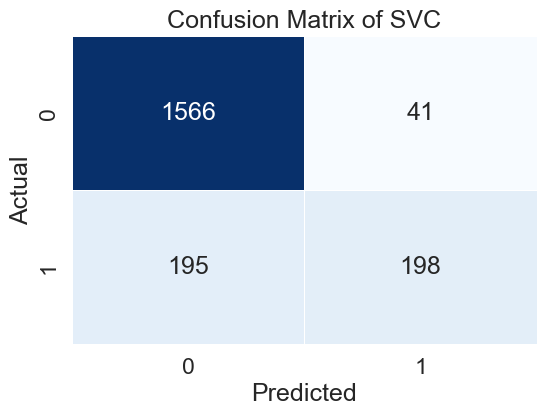

In [57]:
from sklearn.metrics import confusion_matrix
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', linewidths=.5, cbar=False)
plt.title('Confusion Matrix of SVC')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Professional insight

**Confusion-matrix insight – SVC:** This heatmap displays the SVC's true/false predictions. Read rows as actual classes and columns as predicted classes; the top-left and bottom-right cells are correct predictions, while the off-diagonal cells are errors. Use the matrix to understand false alarms and missed churners. Because the SVC tuning process included the test data, this matrix is also provisional and should be regenerated after a leakage-free evaluation.


In [58]:
knn = KNeighborsClassifier(n_neighbors= 3)
knn.fit(X_train,y_train)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


### Professional insight

**Model insight – K-Nearest Neighbours:** KNN is trained with three neighbours. It classifies a customer based on the labels of nearby observations in feature space. Scaling is particularly important for KNN because distance calculations are sensitive to feature magnitude. The model's performance should be compared with other approaches using the same valid split and evaluation metrics.


In [59]:
print(knn.score(X_train, y_train))

0.9323473882945249


### Professional insight

**KNN training-performance insight:** KNN achieves approximately 93.23% accuracy on the resampled training data. This is substantially higher than its test accuracy, suggesting that the model may be fitting the training observations too closely. Since SMOTE creates synthetic training examples, KNN may also learn local patterns that do not generalise well to real customers.


In [60]:
print(knn.score(X_test,y_test))

0.7705


### Professional insight

**KNN test-performance insight:** KNN achieves 77.05% test accuracy. This is below the 79.63% majority-class baseline, so accuracy alone does not demonstrate an improvement over predicting retention for everyone. The precision and recall results are still useful for understanding its ability to identify churners.


In [61]:
y_pred = knn.predict(X_test)

### Professional insight

**Purpose:** This cell generates KNN predictions for the test set. These predictions are used in the following metric and confusion-matrix calculations to assess how well the model identifies exited customers.


In [62]:
knn_acc = accuracy_score(y_test, y_pred)
knn_per = precision_score(y_test, y_pred)
knn_rec = recall_score(y_test, y_pred)
print(f"KNN model accuracy score : {knn_acc}")
print(f"KNN model precision score : {knn_per}")
print(f"KNN model recall score : {knn_rec}")

KNN model accuracy score : 0.7705
KNN model precision score : 0.44021739130434784
KNN model recall score : 0.6183206106870229


### Professional insight

**KNN evaluation:** The model achieves 77.05% accuracy, 44.02% precision and 61.83% recall. It identifies a little over three-fifths of actual churners, while fewer than half of its churn alerts are correct. The recall is useful for detection, but the low precision suggests that a retention team would need to investigate many customers who ultimately stay.


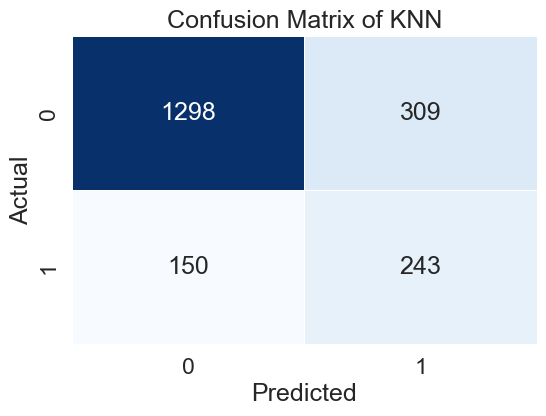

In [63]:
from sklearn.metrics import confusion_matrix
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', linewidths=.5, cbar=False)
plt.title('Confusion Matrix of KNN')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Professional insight

**Confusion-matrix insight – KNN:** The heatmap shows correct retained predictions, false churn alerts, missed churners and correctly detected churners. Focus on the bottom-left cell (actual churners predicted to stay) when assessing missed retention opportunities, and the top-right cell (retained customers predicted to churn) when assessing unnecessary interventions. The matrix should be interpreted alongside KNN's 44.02% precision and 61.83% recall.


In [64]:
clf = DecisionTreeClassifier(max_depth= 5, min_impurity_decrease=0.01,random_state=42)
clf.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.01
,class_weight,None


### Professional insight

**Model insight – Decision Tree:** A Decision Tree is trained with a maximum depth of five and a minimum impurity decrease of 0.01. Limiting depth constrains model complexity and can reduce overfitting while making decision paths easier to interpret. The model can capture nonlinear relationships and interactions, although its results may be sensitive to the training sample.


In [65]:
print(clf.score(X_train, y_train))

0.7178256765261171


### Professional insight

**Decision Tree training-performance insight:** The model achieves approximately 71.78% training accuracy. This is relatively low and suggests that the depth and impurity constraints produce a comparatively simple model. A lower training score is not automatically bad; the key question is whether the model generalises and identifies churners effectively on unseen data.


In [66]:
print(clf.score(X_test, y_test))

0.743


### Professional insight

**Decision Tree test-performance insight:** The model achieves 74.30% test accuracy, slightly higher than its training score. This does not show the usual pattern of overfitting; rather, the constrained tree may be underfitting or the resampled and original class distributions may explain the difference. Compare its precision and recall before assessing practical usefulness.


In [67]:
y_pred = clf.predict(X_test)

### Professional insight

**Purpose:** This cell predicts the churn class for each observation in the test set using the trained Decision Tree. The resulting labels are used to calculate classification metrics and the confusion matrix.


In [68]:
clf_acc = accuracy_score(y_test, y_pred)
clf_per = precision_score(y_test, y_pred)
clf_rec = recall_score(y_test, y_pred)
print(f"Decision tree model accuracy score : {clf_acc}")
print(f"Decision tree model precision score : {clf_per}")
print(f"Decision tree model recall score : {clf_rec}")

Decision tree model accuracy score : 0.743
Decision tree model precision score : 0.4111600587371512
Decision tree model recall score : 0.712468193384224


### Professional insight

**Decision Tree evaluation:** The model records 74.30% accuracy, 41.12% precision and 71.25% recall. Its recall is relatively high compared with several other models, meaning it identifies a substantial share of actual churners. Precision is low, however, so many flagged customers did not exit. This may be acceptable when missing a churner is more costly than contacting a customer who stays.


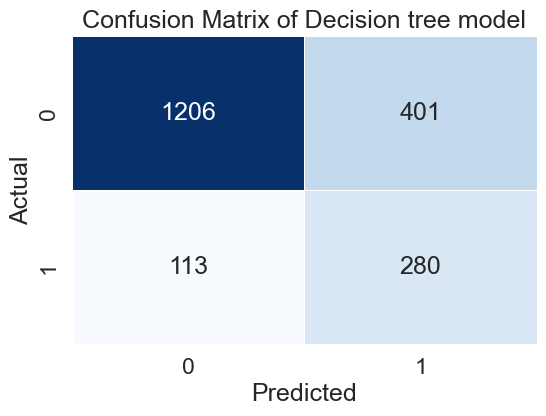

In [69]:
from sklearn.metrics import confusion_matrix
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', linewidths=.5, cbar=False)
plt.title('Confusion Matrix of Decision tree model')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Professional insight

**Confusion-matrix insight – Decision Tree:** The matrix shows the Decision Tree's correct and incorrect predictions for each class. Examine false negatives to see how many actual churners were missed, and false positives to understand the volume of unnecessary retention alerts. The relatively high recall (71.25%) should be considered alongside the modest precision (41.12%).


In [70]:
rf_classifier = RandomForestClassifier(n_estimators= 100, min_impurity_decrease=0.01)
rf_classifier.fit(X_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.01
,bootstrap,True
,oob_score,False


### Professional insight

**Model insight – Random Forest:** Random Forest combines predictions from 100 decision trees to reduce the instability of a single tree. The `min_impurity_decrease` setting restricts splits that provide only a small improvement. This ensemble can capture nonlinear patterns, but its performance still needs to be validated on unseen data.


In [71]:
rf_classifier.score(X_train, y_train)

0.7667558212712398

### Professional insight

**Random Forest training-performance insight:** Random Forest achieves approximately 76.68% accuracy on the resampled training set. This indicates a moderate fit to the balanced training data. Comparing it with the test score helps assess generalisation; the two scores are close in this notebook.


In [72]:
rf_classifier.score(X_test,y_test)

0.772

### Professional insight

**Random Forest test-performance insight:** The model achieves 77.20% test accuracy. This is below the 79.63% majority-class baseline, so the accuracy result alone is not strong. Its recall and precision provide a more useful view of its ability to detect churners.


In [73]:
y_pred = rf_classifier.predict(X_test)

### Professional insight

**Purpose:** This cell generates Random Forest predictions for the test set. The predictions are used to calculate accuracy, precision, recall and the confusion matrix.


In [74]:
rf_acc = accuracy_score(y_test, y_pred)
rf_per = precision_score(y_test, y_pred)
rf_rec = recall_score(y_test, y_pred)
print(f"Random Forest Classifier accuracy score: {rf_acc}")
print(f"Random Forest Classifier precision score: {rf_per}")
print(f"Random Forest Classifier recall score: {rf_rec}")

Random Forest Classifier accuracy score: 0.772
Random Forest Classifier precision score: 0.45131375579598143
Random Forest Classifier recall score: 0.7430025445292621


### Professional insight

**Random Forest evaluation:** The model achieves 77.20% accuracy, 45.13% precision and 74.30% recall. It detects nearly three-quarters of actual churners, which is useful when the priority is to minimise missed exits. However, less than half of the customers flagged as churners actually exited, so the retention team would need to manage false-positive alerts.


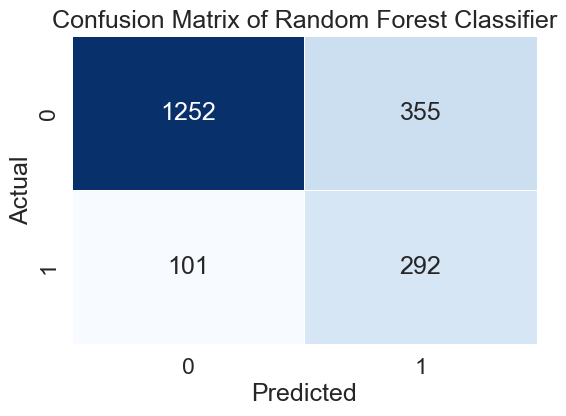

In [75]:
from sklearn.metrics import confusion_matrix
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', linewidths=.5, cbar=False)
plt.title('Confusion Matrix of Random Forest Classifier')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Professional insight

**Confusion-matrix insight – Random Forest:** The heatmap shows how many retained and exited customers were classified correctly or incorrectly. The lower-left cell represents missed churners, while the upper-right cell represents false churn alerts. Use these counts to translate the 74.30% recall and 45.13% precision into operational workload and missed-customer risk.


In [76]:
base_classifier = DecisionTreeClassifier(min_impurity_decrease=0.01)
bagging_classifier = BaggingClassifier(base_classifier,n_estimators=10)
bagging_classifier.fit(X_train,y_train)

,estimator,DecisionTreeC...decrease=0.01)
,n_estimators,10
,max_samples,1.0
,max_features,1.0
,bootstrap,True
,bootstrap_features,False
,oob_score,False
,warm_start,False
,n_jobs,None
,random_state,None
,verbose,0


### Professional insight

**Model insight – Bagging Classifier:** Bagging trains multiple versions of a base Decision Tree on different bootstrap samples and aggregates their predictions. This can reduce the variance of an individual tree. Here, the base tree uses a minimum impurity decrease of 0.01 and the ensemble contains 10 estimators. Performance should be judged against the other models on the same test set.


In [77]:
bagging_classifier.score(X_train,y_train)

0.7357614852108244

### Professional insight

**Bagging training-performance insight:** The Bagging model achieves approximately 73.58% training accuracy. This indicates a relatively constrained fit on the resampled training data. Its test result is close, suggesting no large train-test accuracy gap in this run.


In [78]:
bagging_classifier.score(X_test,y_test)

0.741

### Professional insight

**Bagging test-performance insight:** The model achieves 74.10% test accuracy. This is below the majority-class baseline of 79.63%, so overall accuracy is not competitive. Its recall and precision should be examined to determine whether it offers value for identifying churners despite the lower accuracy.


In [79]:
y_pred = bagging_classifier.predict(X_test)

### Professional insight

**Purpose:** This cell generates Bagging Classifier predictions for the test observations. The predictions are then evaluated using classification metrics and a confusion matrix.


In [80]:
bag_acc = accuracy_score(y_test, y_pred)
bag_per = precision_score(y_test, y_pred)
bag_rec = recall_score(y_test, y_pred)
print(f"Bagging Classifier accuracy score: {bag_acc}")
print(f"Bagging Classifier precision score: {bag_per}")
print(f"Bagging Classifier recall score: {bag_rec}")

Bagging Classifier accuracy score: 0.741
Bagging Classifier precision score: 0.4118476727785614
Bagging Classifier recall score: 0.7430025445292621


### Professional insight

**Bagging evaluation:** The model achieves 74.10% accuracy, 41.18% precision and 74.30% recall. Its relatively high recall means it identifies many actual churners, but its precision indicates that a substantial proportion of its churn alerts are false positives. This may create a high follow-up workload for the retention team.


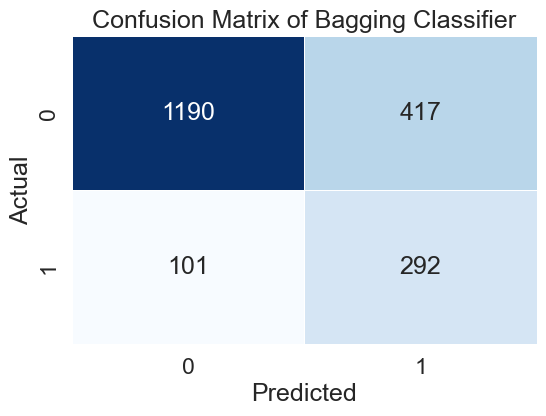

In [81]:
from sklearn.metrics import confusion_matrix
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', linewidths=.5, cbar=False)
plt.title('Confusion Matrix of Bagging Classifier')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Professional insight

**Confusion-matrix insight – Bagging:** The matrix separates correct predictions from false alarms and missed churners. Pay particular attention to false negatives because they represent customers who exited without being flagged, and false positives because they represent unnecessary retention contacts. The matrix should support the interpretation of the model's 74.30% recall and 41.18% precision.


In [82]:
ET_classifier = ExtraTreesClassifier(n_estimators=100, min_impurity_decrease=0.01)
ET_classifier.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.01
,bootstrap,False
,oob_score,False


### Professional insight

**Model insight – Extra Trees:** Extra Trees is an ensemble of highly randomised decision trees. Randomisation can reduce variance and produce diverse trees, while 100 estimators combine their predictions. The minimum impurity decrease setting also limits weak splits. Its value should be judged by test-set performance rather than model complexity alone.


In [83]:
ET_classifier.score(X_train,y_train)

0.7459880427942102

### Professional insight

**Extra Trees training-performance insight:** Extra Trees achieves approximately 74.60% training accuracy. This is close to its reported test accuracy, suggesting a relatively small train-test gap. A small gap is not sufficient by itself to establish good performance; both scores and the churn-class metrics must be considered.


In [84]:
ET_classifier.score(X_test,y_test)

0.734

### Professional insight

**Extra Trees test-performance insight:** The model achieves 73.40% test accuracy, the lowest reported accuracy among the models in the comparison. This is below the majority-class baseline. Its precision and recall indicate whether it detects churners despite the weak overall accuracy, but it is not a leading candidate based on the current results.


In [85]:
y_pred_et = ET_classifier.predict(X_test)

### Professional insight

**Purpose:** This cell generates test-set predictions using the Extra Trees model. The variable `y_pred_et` is kept separate from the predictions of other models so that its metrics and confusion matrix can be evaluated correctly.


In [86]:
et_acc = accuracy_score(y_test, y_pred_et)
et_per = precision_score(y_test, y_pred_et)
et_rec = recall_score(y_test, y_pred_et)
print(f"Extra Tree Classifier accuracy score: {et_acc}")
print(f"Extra Tree Classifier precision score: {et_per}")
print(f"Extra Tree Classifier recall score: {et_rec}")

Extra Tree Classifier accuracy score: 0.734
Extra Tree Classifier precision score: 0.3954887218045113
Extra Tree Classifier recall score: 0.6692111959287532


### Professional insight

**Extra Trees evaluation:** The model records 73.40% accuracy, 39.55% precision and 66.92% recall. It identifies about two-thirds of actual churners, but fewer than four in ten churn alerts are correct. The combination of relatively low precision and the lowest reported accuracy makes it less compelling than several alternatives in this experiment.


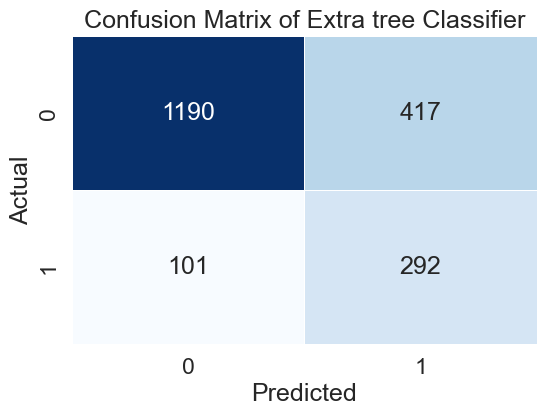

In [87]:
from sklearn.metrics import confusion_matrix
conf_matrix_et = confusion_matrix(y_test, y_pred_et)

plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', linewidths=.5, cbar=False)
plt.title('Confusion Matrix of Extra tree Classifier')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Professional insight

**Confusion-matrix code correction:** This cell correctly calculates `conf_matrix_et`, but the heatmap call uses `conf_matrix` instead. As a result, the displayed diagram may show a previous model's matrix rather than Extra Trees' results. Change the heatmap argument to `conf_matrix_et` and rerun the cell before interpreting the chart. The corrected matrix is necessary for a valid model-specific discussion.


In [88]:
AB_classifier = AdaBoostClassifier(n_estimators=100)
AB_classifier.fit(X_train, y_train)

,estimator,None
,n_estimators,100
,learning_rate,1.0
,algorithm,'deprecated'
,random_state,None


### Professional insight

**Model insight – AdaBoost:** AdaBoost combines 100 sequential weak learners, with later learners focusing more on observations that earlier learners classified incorrectly. This approach can improve detection of difficult cases. Its effectiveness should be evaluated through the trade-off between correctly identifying churners and generating false alerts.


In [89]:
AB_classifier.score(X_train, y_train)

0.8001887979861548

### Professional insight

**AdaBoost training-performance insight:** AdaBoost achieves approximately 80.02% accuracy on the resampled training data. This is higher than its test accuracy, but the difference is not especially large compared with the gaps observed for some boosting models. Cross-validation would provide a more stable estimate of its generalisation.


In [90]:
AB_classifier.score(X_test, y_test)

0.79

### Professional insight

**AdaBoost test-performance insight:** The model achieves 79.00% test accuracy, slightly below the 79.63% majority-class baseline. Accuracy alone therefore does not show an improvement over the simplest baseline. Its comparatively high recall may still make it useful when the priority is to detect as many churners as possible.


In [91]:
y_pred_ab = AB_classifier.predict(X_test)

### Professional insight

**Purpose:** This cell generates AdaBoost predictions for the test set and stores them in `y_pred_ab`. The following cells use these predictions to evaluate the model's classification performance.


In [92]:
ada_acc = accuracy_score(y_test, y_pred_ab)
ada_per = precision_score(y_test, y_pred_ab)
ada_rec = recall_score(y_test, y_pred_ab)
print(f"Ada Classifier accuracy score: {ada_acc}")
print(f"Ada Classifier percision score: {ada_per}")
print(f"Ada Classifier recall score: {ada_rec}")

Ada Classifier accuracy score: 0.79
Ada Classifier percision score: 0.4788732394366197
Ada Classifier recall score: 0.7786259541984732


### Professional insight

**AdaBoost evaluation:** The model achieves 79.00% accuracy, 47.89% precision and 77.86% recall. It has the highest recall among the 11 models in this notebook, meaning it detects the largest proportion of actual churners in the reported comparison. Its precision is below 50%, so more than half of its churn alerts are false positives. It is a candidate when missing churners is particularly costly, subject to a corrected and validated evaluation.


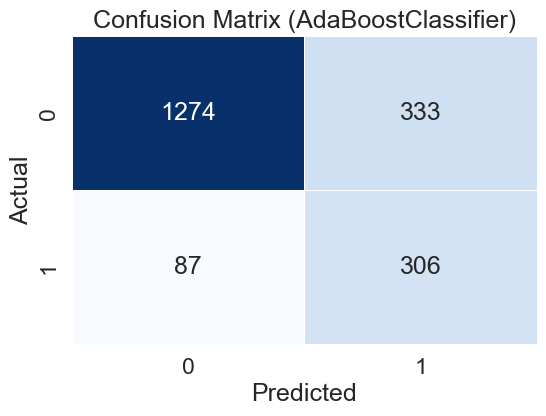

In [93]:
from sklearn.metrics import confusion_matrix
conf_matrix_ab = confusion_matrix(y_test, y_pred_ab)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix_ab, annot=True, fmt='d', cmap='Blues', linewidths=.5, cbar=False)
plt.title('Confusion Matrix (AdaBoostClassifier)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Professional insight

**Confusion-matrix insight – AdaBoost:** The matrix shows the balance between missed churners and false churn alerts. Given the reported recall of 77.86%, the false-negative count should be relatively low compared with models with lower recall. The false-positive count may be substantial, consistent with precision of 47.89%. These errors should be translated into the expected number of customers a retention team would need to contact.


In [94]:
XGB_classifier = XGBClassifier(n_estimators=200)
XGB_classifier.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


### Professional insight

**Model insight – XGBoost:** XGBoost is a gradient-boosted tree ensemble trained here with 200 estimators. It builds trees sequentially, with each stage attempting to improve the errors of the existing ensemble. It can model complex nonlinear relationships, but may overfit if model complexity is not controlled through parameters such as tree depth, learning rate and regularisation.


In [95]:
XGB_classifier.score(X_train,y_train)

0.9899307740717432

### Professional insight

**XGBoost training-performance insight:** XGBoost achieves approximately 98.99% training accuracy, which is extremely high. This suggests that the model fits the resampled training data very closely. Such a high training score should prompt an overfitting check, especially when the test score is substantially lower.


In [96]:
XGB_classifier.score(X_test,y_test)

0.8505

### Professional insight

**XGBoost test-performance insight:** XGBoost achieves 85.05% test accuracy, producing a train-test gap of about 13.94 percentage points. This large gap is a warning sign of overfitting: the model performs almost perfectly on training observations but less well on unseen observations. Regularisation, shallower trees, a lower learning rate, early stopping and cross-validation should be explored.


In [97]:
y_pred_xgb = XGB_classifier.predict(X_test)

### Professional insight

**Purpose:** This cell generates XGBoost predictions for the test observations. These predictions are used in the following evaluation metrics and confusion matrix.


In [98]:
xgb_acc = accuracy_score(y_test, y_pred_xgb)
xgb_per = precision_score(y_test, y_pred_xgb)
xgb_rec = recall_score(y_test, y_pred_xgb)
print(f"XGBClassifier accuracy score : {xgb_acc}")
print(f"XGBClassifier percision score : {xgb_per}")
print(f"XGBClassifier recall score : {xgb_rec}")

XGBClassifier accuracy score : 0.8505
XGBClassifier percision score : 0.6407185628742516
XGBClassifier recall score : 0.544529262086514


### Professional insight

**XGBoost evaluation:** The model reports 85.05% accuracy, 64.07% precision and 54.45% recall. Its precision is relatively strong, but it identifies only a little over half of actual churners. Combined with the large training-test accuracy gap, this suggests that the model needs further tuning and validation before deployment.


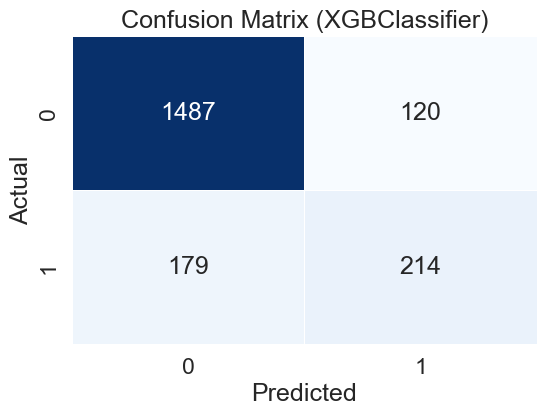

In [99]:
from sklearn.metrics import confusion_matrix
conf_matrix_xgb = confusion_matrix(y_test, y_pred_xgb)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix_xgb, annot=True, fmt='d', cmap='Blues', linewidths=.5, cbar=False)
plt.title('Confusion Matrix (XGBClassifier)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Professional insight

**Confusion-matrix insight – XGBoost:** The matrix shows the number of correctly identified retained customers and churners, together with false alarms and missed churners. The reported recall of 54.45% means that a substantial proportion of actual churners are still missed. The matrix can help determine whether this is caused by many false negatives or another classification trade-off, and should be considered alongside the overfitting evidence.


In [100]:
CatBoost_classifier = CatBoostClassifier(iterations=100, learning_rate=0.1, depth=6)
CatBoost_classifier.fit(X_train, y_train)

0:	learn: 0.6558264	total: 232ms	remaining: 23s
1:	learn: 0.6255098	total: 245ms	remaining: 12s
2:	learn: 0.5982137	total: 273ms	remaining: 8.84s
3:	learn: 0.5770465	total: 293ms	remaining: 7.03s
4:	learn: 0.5574065	total: 305ms	remaining: 5.8s
5:	learn: 0.5409075	total: 323ms	remaining: 5.06s
6:	learn: 0.5286027	total: 340ms	remaining: 4.51s
7:	learn: 0.5175869	total: 354ms	remaining: 4.07s
8:	learn: 0.5075540	total: 371ms	remaining: 3.75s
9:	learn: 0.4978899	total: 388ms	remaining: 3.49s
10:	learn: 0.4893601	total: 406ms	remaining: 3.28s
11:	learn: 0.4823757	total: 422ms	remaining: 3.09s
12:	learn: 0.4765071	total: 438ms	remaining: 2.93s
13:	learn: 0.4699199	total: 453ms	remaining: 2.78s
14:	learn: 0.4641558	total: 465ms	remaining: 2.63s
15:	learn: 0.4591026	total: 475ms	remaining: 2.49s
16:	learn: 0.4556528	total: 486ms	remaining: 2.37s
17:	learn: 0.4506462	total: 507ms	remaining: 2.31s
18:	learn: 0.4472239	total: 523ms	remaining: 2.23s
19:	learn: 0.4445149	total: 553ms	remaining: 2

CatBoostClassifier(depth=6, iterations=100, learning_rate=0.1)

### Professional insight

**Model insight – CatBoost:** CatBoost is a gradient-boosting algorithm designed to handle categorical data effectively. In this notebook, the data has already been one-hot encoded, and CatBoost is configured with 100 iterations, a learning rate of 0.1 and depth 6. The training log shows the learning process progressing across iterations. Its performance should be judged by the gap between training and test results and its churn-class metrics.


In [101]:
CatBoost_classifier.score(X_train, y_train)

np.float64(0.8654027690371303)

### Professional insight

**CatBoost training-performance insight:** CatBoost achieves approximately 86.54% training accuracy. This is much closer to its test accuracy than the training scores reported for XGBoost and LightGBM, suggesting less pronounced overfitting in this run. A small gap is encouraging but should still be confirmed with stratified cross-validation.


In [102]:
CatBoost_classifier.score(X_test,y_test)

np.float64(0.8415)

### Professional insight

**CatBoost test-performance insight:** CatBoost achieves 84.15% test accuracy. The difference from its training accuracy is approximately 2.39 percentage points, indicating relatively consistent performance between the two sets. Its precision and recall are needed to understand how effectively it identifies churners, not just overall correct predictions.


In [103]:
y_pred_catboost = CatBoost_classifier.predict(X_test)

### Professional insight

**Purpose:** This cell generates CatBoost predictions for the test set. The predicted labels are used to calculate classification metrics and the confusion matrix.


In [104]:
cat_acc = accuracy_score(y_test, y_pred_catboost)
cat_per = precision_score(y_test, y_pred_catboost)
cat_rec = recall_score(y_test, y_pred_catboost)
print(f"CatBoost Classifier accuracy score:{cat_acc}")
print(f"CatBoost Classifier percision score:{cat_per}")
print(f"CatBoost Classifier recall score:{cat_rec}")

CatBoost Classifier accuracy score:0.8415
CatBoost Classifier percision score:0.5781893004115226
CatBoost Classifier recall score:0.7150127226463104


### Professional insight

**CatBoost evaluation:** The model records 84.15% accuracy, 57.82% precision and 71.50% recall. It identifies a substantial proportion of actual churners while achieving higher precision than Logistic Regression, KNN, Decision Tree, Random Forest, Bagging and Extra Trees in the reported results. This makes CatBoost a promising candidate for further validation when a balance between churn detection and false alerts is required.


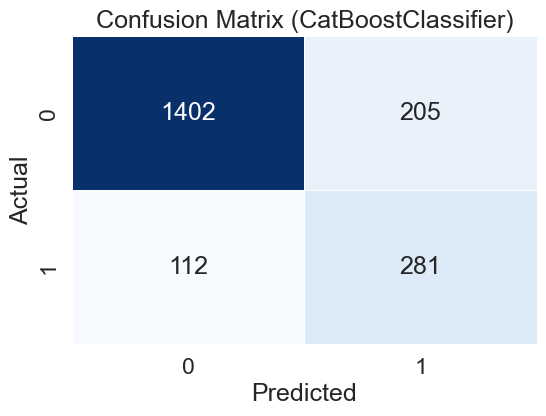

In [105]:
from sklearn.metrics import confusion_matrix
conf_matrix_catboost = confusion_matrix(y_test, y_pred_catboost)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix_catboost, annot=True, fmt='d', cmap='Blues', linewidths=.5, cbar=False)
plt.title('Confusion Matrix (CatBoostClassifier)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Professional insight

**Confusion-matrix insight – CatBoost:** The matrix shows the number of correct and incorrect predictions for both customer classes. The reported recall of 71.50% indicates that just over seven in ten actual churners are detected, while precision of 57.82% means that more than half of churn alerts are correct. This may represent a practical trade-off, but the final choice should depend on retention-intervention costs and validated test performance.


In [106]:
LGBM_classifier = LGBMClassifier(n_estimators=300)
LGBM_classifier.fit(X_train, y_train)

[LightGBM] [Info] Number of positive: 6356, number of negative: 6356
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001173 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1294
[LightGBM] [Info] Number of data points in the train set: 12712, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,300
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


### Professional insight

**Model insight – LightGBM:** LightGBM is a gradient-boosting decision-tree algorithm, configured here with 300 estimators. It is designed for efficient training on structured data and can capture nonlinear feature relationships. Its high training accuracy should be compared with the test result to assess whether the model generalises.


In [107]:
LGBM_classifier.score(X_train, y_train)

0.9787602265575834

### Professional insight

**LightGBM training-performance insight:** LightGBM achieves approximately 97.88% training accuracy. This is very high and suggests that the model fits the resampled training observations closely. The difference from its test accuracy is substantial, so overfitting should be investigated through regularisation, tree constraints, early stopping and cross-validation.


In [108]:
LGBM_classifier.score(X_test, y_test)

0.866

### Professional insight

**LightGBM test-performance insight:** LightGBM achieves 86.60% test accuracy, the highest reported accuracy in the notebook apart from the SVC result. Its training accuracy is approximately 97.88%, creating a gap of about 11.28 percentage points. This indicates possible overfitting. In addition, the SVC result is not directly comparable because its hyperparameter search used the full dataset. LightGBM is a strong candidate for further tuning, not yet a validated winner.


In [109]:
y_pred_lgbm = LGBM_classifier.predict(X_test)

### Professional insight

**Purpose:** This cell generates LightGBM predictions for the test observations. These predictions are used to calculate the model's accuracy, precision, recall and confusion matrix.


In [110]:
lgbm_acc = accuracy_score(y_test, y_pred_lgbm)
lgbm_per = precision_score(y_test, y_pred_lgbm)
lgbm_rec = recall_score(y_test, y_pred_lgbm)
print(f"LGBM Classifier accuracy score : {lgbm_acc}")
print(f"LGBM Classifier percision score : {lgbm_per}")
print(f"LGBM Classifier recall score : {lgbm_rec}")

LGBM Classifier accuracy score : 0.866
LGBM Classifier percision score : 0.6996805111821086
LGBM Classifier recall score : 0.5572519083969466


### Professional insight

**LightGBM evaluation:** The model achieves 86.60% accuracy, 69.97% precision and 55.73% recall. It has the strongest reported precision among the models in the comparison, excluding the SVC result which is affected by test-set leakage. However, its recall means it misses a considerable share of actual churners. The model may suit a strategy that prioritises reliable alerts over detecting every possible churner, but its overfitting and preprocessing pipeline must be addressed first.


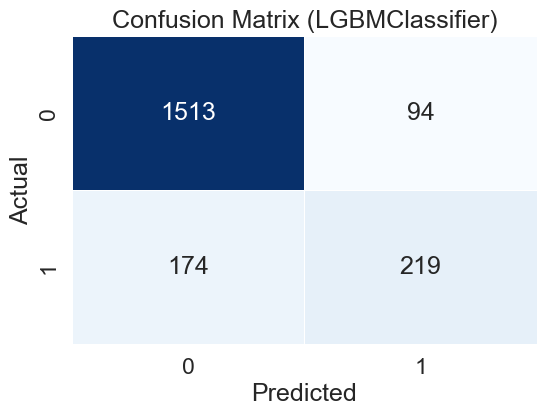

In [111]:
from sklearn.metrics import confusion_matrix
conf_matrix_lgbm = confusion_matrix(y_test, y_pred_lgbm)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix_lgbm, annot=True, fmt='d', cmap='Blues', linewidths=.5, cbar=False)
plt.title('Confusion Matrix (LGBMClassifier)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Professional insight

**Confusion-matrix insight – LightGBM:** The matrix shows the correct predictions and the two types of error. The reported precision of 69.97% indicates that churn alerts are more reliable than those from most other models, while recall of 55.73% indicates that many actual churners are still missed. The bank should decide whether fewer false alarms or broader churn detection is more valuable before selecting a threshold or model.


In [113]:
Models = ['LogisticRegression', 'SVC', 'KNN', 'DecisionTreeClassifier', 'RandomForestClassifier', 'BaggingClassifier',
         'ExtraTreesClassifier', 'XGBoostClassifier', 'AdaBoostClassifier', 'CatBoostClassifier', 'LGBMClassifier']
Accuracy = [lr_acc, svc_acc, knn_acc, clf_acc, rf_acc, bag_acc, et_acc, xgb_acc, ada_acc, cat_acc, lgbm_acc]
Precision = [lr_pre, svc_per, knn_per, clf_per, rf_per, bag_per, et_per, xgb_per, ada_per, cat_per, lgbm_per]
Recall = [lr_rec, svc_rec, knn_rec, clf_rec, rf_rec, bag_rec, et_rec, xgb_rec, ada_rec, cat_rec, lgbm_rec]
Models = pd.DataFrame(data={"Models":Models,"Accuracy":Accuracy,"Percision":Precision,"Recall":Recall})
Models

,Models,Accuracy,Percision,Recall
0,LogisticRegression,0.7390,0.400922,0.664122
1,SVC,0.8820,0.828452,0.503817
2,KNN,0.7705,0.440217,0.618321
3,DecisionTreeClassifier,0.7430,0.411160,0.712468
4,RandomForestClassifier,0.7720,0.451314,0.743003
5,BaggingClassifier,0.7410,0.411848,0.743003
6,ExtraTreesClassifier,0.7340,0.395489,0.669211
7,XGBoostClassifier,0.8505,0.640719,0.544529
8,AdaBoostClassifier,0.7900,0.478873,0.778626
9,CatBoostClassifier,0.8415,0.578189,0.715013


### Professional insight

**Model-comparison insight:** The table compares all 11 algorithms using accuracy, precision and recall. LightGBM has the highest reported accuracy (86.60%) and the strongest reported precision among the models whose evaluation is not affected by the SVC tuning leakage; AdaBoost has the highest reported recall (77.86%). CatBoost provides a comparatively balanced profile (84.15% accuracy, 57.82% precision and 71.50% recall) and a smaller training-test accuracy gap than XGBoost and LightGBM. However, SVC's 88.20% accuracy is not a fair independent test result because its GridSearchCV was fitted on the full dataset. The comparison also needs F1-score, ROC-AUC and PR-AUC, stratified cross-validation, and a leakage-free preprocessing pipeline. The best model should be selected according to the business cost of false positives and false negatives, not accuracy alone.
